# Hierarchical Clustering

## Intuition

Hierarchical Clustering builds a **tree of clusters** (called a dendrogram) by either:

- **Agglomerative** (bottom-up): Start with individual points and **merge** them step by step.
- **Divisive** (top-down): Start with one cluster and **split** it recursively.

We focus on **Agglomerative Clustering**, the most common approach.

No need to specify number of clusters initially, you can "cut" the dendrogram at any height.


## Mathematical Foundation

The clustering is based on **distance between points or clusters**.

### Distance Metrics:
- **Euclidean** (default): $d(x, y) = \sqrt{\sum (x_i - y_i)^2}$
- Manhattan, Cosine, etc.

### Linkage Criteria:
Defines distance between clusters:
- **Single Linkage**: min distance between any pair of points
- **Complete Linkage**: max distance between any pair
- **Average Linkage**: mean distance
- **Ward’s Method**: minimizes within-cluster variance (similar to K-Means)

Most common: **Ward’s method + Euclidean distance**

## Agglomerative Hierarchical Clustering Steps

1. Treat each data point as a **separate cluster**
2. Compute **pairwise distances** between all clusters
3. **Merge** the closest two clusters
4. Recompute distances using chosen **linkage method**
5. Repeat until **all points belong to one cluster**

This process builds a **dendrogram**, and you can cut it at any height to choose number of clusters.

## Do You Need to Specify Number of Clusters?

Unlike K-Means, **Hierarchical Clustering builds the full hierarchy first** (as a dendrogram), without needing to predefine the number of clusters.

However, to assign **final cluster labels** (i.e., cut the dendrogram), you **do need to specify the number of clusters (`k`) or a cut-off distance**.

So:
- You **don’t need to guess `k` before building** the model.
- You **choose `k` after inspecting the dendrogram visually.**


## Linkage Methods in Agglomerative Clustering

In hierarchical (agglomerative) clustering, **linkage methods** determine how the distance between two clusters is calculated when merging. Below are the four common linkage strategies:

---

### 1. **Ward Linkage**
- **Goal**: Minimize the total within-cluster **variance** (inertia).
- **Merging Criterion**: Choose the pair of clusters whose merger results in the **smallest increase** in total within-cluster **sum of squared errors (SSE)**.
- **Characteristics**:
  - Tends to create **compact and equally-sized** clusters.
  - Only supports **Euclidean distance**.

---

### 2. **Single Linkage (Minimum Linkage)**
- **Goal**: Merge clusters with the **closest pair of points**.
- **Characteristics**:
  - Can create **chained clusters** (loose, elongated shapes).
  - Sensitive to noise and outliers.

---

### 3. **Complete Linkage (Maximum Linkage)**
- **Goal**: Merge clusters with the **farthest pair of points**.
- **Characteristics**:
  - Produces **compact and spherical** clusters.
  - Sensitive to **outliers** and may break large clusters.

---

### 4. **Average Linkage (UPGMA)**
- **Goal**: Merge clusters based on the **average distance** between all pairs of points.
- **Characteristics**:
  - Balanced between single and complete.
  - Produces reasonable clustering in many cases.

---

### Summary Table

| Linkage Type | Based On         | Behavior                          |
|--------------|------------------|-----------------------------------|
| Ward         | Variance (SSE)   | Compact, equal-sized clusters     |
| Single       | Closest points   | Chained clusters, sensitive       |
| Complete     | Farthest points  | Tight clusters, sensitive         |
| Average      | Avg. pairwise    | Balanced merging strategy         |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch

from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris, make_blobs
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

## Synthetic example

Three well-separated blobs; `y_true` is kept only to *check* the result, never to fit it.

In [2]:
# Create synthetic dataset
X, y_true = make_blobs(n_samples=25, centers=3, cluster_std=1.0, random_state=42)

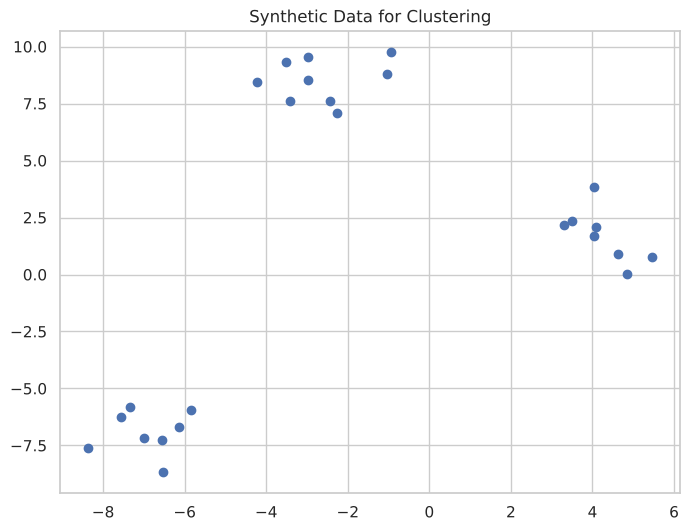

In [3]:
# Plot
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1])
plt.title("Synthetic Data for Clustering")
plt.grid(True)
plt.show()

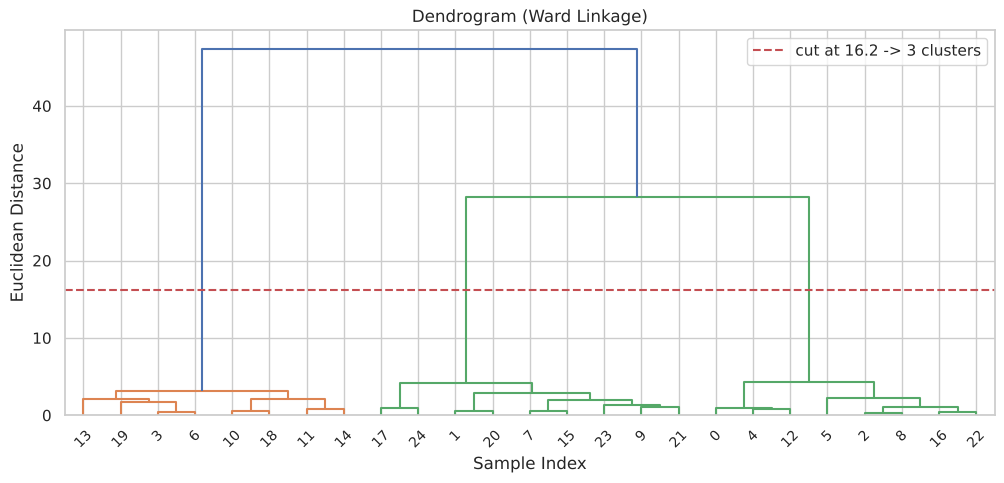

In [4]:
# Dendrogram. The dashed line is the cut that yields 3 clusters (between the 3rd- and 2nd-last merge).
Z = sch.linkage(X, method='ward')
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(12, 5))
sch.dendrogram(Z)
plt.axhline(cut_height, color='r', linestyle='--', label=f'cut at {cut_height:.1f} -> 3 clusters')
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")
plt.legend()
plt.show()

In [5]:
# Apply Agglomerative Clustering (cut dendrogram at n_clusters=3)
agg_clust = AgglomerativeClustering(n_clusters=3, linkage='ward')
y_pred = agg_clust.fit_predict(X)

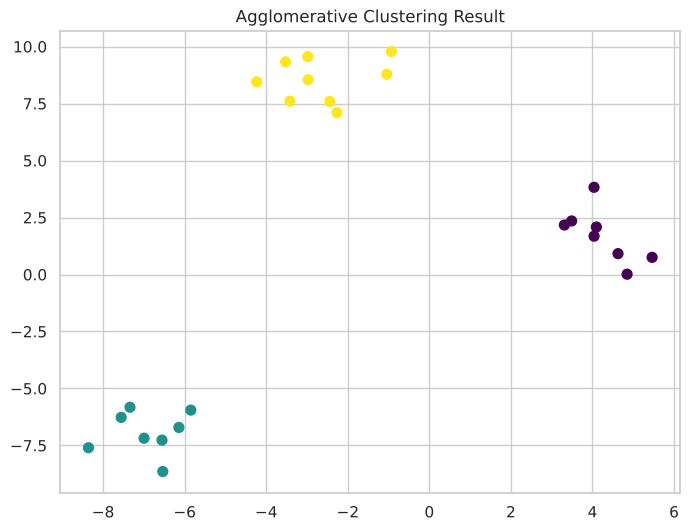

In [6]:
# Plot clusters
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Result")
plt.grid(True)
plt.show()

In [7]:
print(f"Adjusted Rand index vs. generating blobs: {adjusted_rand_score(y_true, y_pred):.3f}")
print(f"Silhouette (internal, no labels needed):     {silhouette_score(X, y_pred):.3f}")

Adjusted Rand index vs. generating blobs: 1.000
Silhouette (internal, no labels needed):     0.835


## Iris dataset

The Iris species labels are used **only for external validation** after clustering. Because clustering has no train/test split, the honest questions are: (1) is the structure stable and well-defined (internal metrics such as the silhouette score), and (2) does it agree with known labels when we have them (adjusted Rand index, normalised mutual information).

In [8]:
# Load Iris dataset
iris = load_iris()
X_iris = iris.data
df = pd.DataFrame(X_iris, columns=iris.feature_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Do features need scaling?

Ward linkage uses Euclidean distance, so features on larger scales dominate. All four Iris measurements are in centimetres with similar ranges, but the sepal/petal lengths vary more than the widths. Both variants are run and compared rather than assuming.

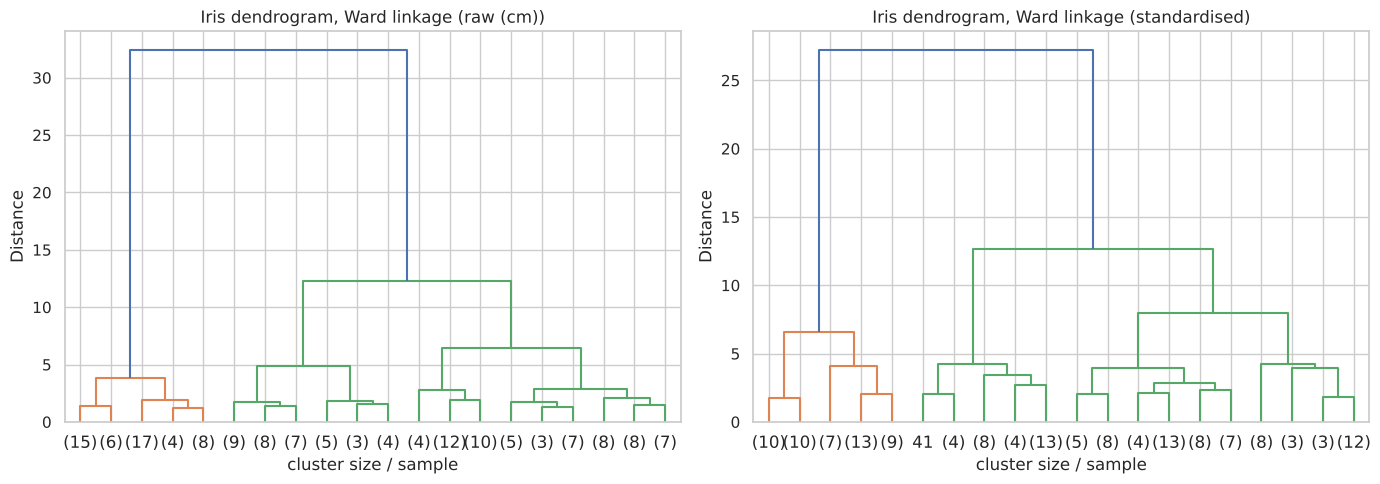

In [9]:
iris_raw = iris.data
iris_scaled = StandardScaler().fit_transform(iris.data)   # no train/test split in clustering: scaling the whole set is legitimate here
true_labels = iris.target

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, data_) in zip(axes, [('raw (cm)', iris_raw), ('standardised', iris_scaled)]):
    Zi = sch.linkage(data_, method='ward')
    sch.dendrogram(Zi, truncate_mode='lastp', p=20, ax=ax)   # last 20 merges only: the full 150-leaf tree is unreadable
    ax.set_title(f"Iris dendrogram, Ward linkage ({name})"); ax.set_xlabel("cluster size / sample"); ax.set_ylabel("Distance")
plt.tight_layout(); plt.show()

### Choosing the linkage and the number of clusters

For each linkage and each k in 2-6, the table shows the silhouette score (internal), plus the adjusted Rand index against the species (external, for reference only). The cophenetic correlation says how faithfully each dendrogram preserves the original pairwise distances.

In [10]:
rows = []
for data_name, data_ in [('raw', iris_raw), ('standardised', iris_scaled)]:
    for link in ['ward', 'average', 'complete', 'single']:
        Zl = sch.linkage(data_, method=link)
        coph = sch.cophenet(Zl, pdist(data_))[0]
        for k in range(2, 7):
            lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(data_)
            rows.append((data_name, link, k, coph, silhouette_score(data_, lab), adjusted_rand_score(true_labels, lab)))
grid = pd.DataFrame(rows, columns=['features', 'linkage', 'k', 'cophenetic_corr', 'silhouette', 'ARI_vs_species'])
display(grid[grid.k == 3].drop(columns='k').round(3).reset_index(drop=True))

best_k = grid.groupby('k').silhouette.max()
print("Best silhouette per k (across linkages/features):"); print(best_k.round(3).to_string())

Best silhouette per k (across linkages/features):
k
2    0.687
3    0.554
4    0.500
5    0.484
6    0.359


,features,linkage,cophenetic_corr,silhouette,ARI_vs_species
0,raw,ward,0.873,0.554,0.731
1,raw,average,0.877,0.554,0.759
2,raw,complete,0.727,0.514,0.642
3,raw,single,0.864,0.512,0.564
4,standardised,ward,0.823,0.447,0.615
5,standardised,average,0.854,0.480,0.562
6,standardised,complete,0.751,0.450,0.573
7,standardised,single,0.830,0.505,0.558


**Reading the table.** Silhouette typically peaks at k = 2 on Iris, because *setosa* is far from the other two species while *versicolor* and *virginica* overlap. k = 3 is the biologically meaningful choice (it matches the three species) but it is not the one the internal metric prefers: that is a property of the data, not an error. Standardising did **not** help here (ARI for Ward falls from about 0.73 to 0.62): all four features are in centimetres, and rescaling inflates the weakly informative sepal width. Scaling is a decision to test, not a default. Single linkage chains points together and performs worst on the ARI; Ward and average on the raw measurements are the strongest, so the final model below uses Ward on the raw data.

In [11]:
agg_iris = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = agg_iris.fit_predict(iris_raw)
df['Cluster'] = labels
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


Variance explained by 2 PCs: [0.925 0.053] total 0.978


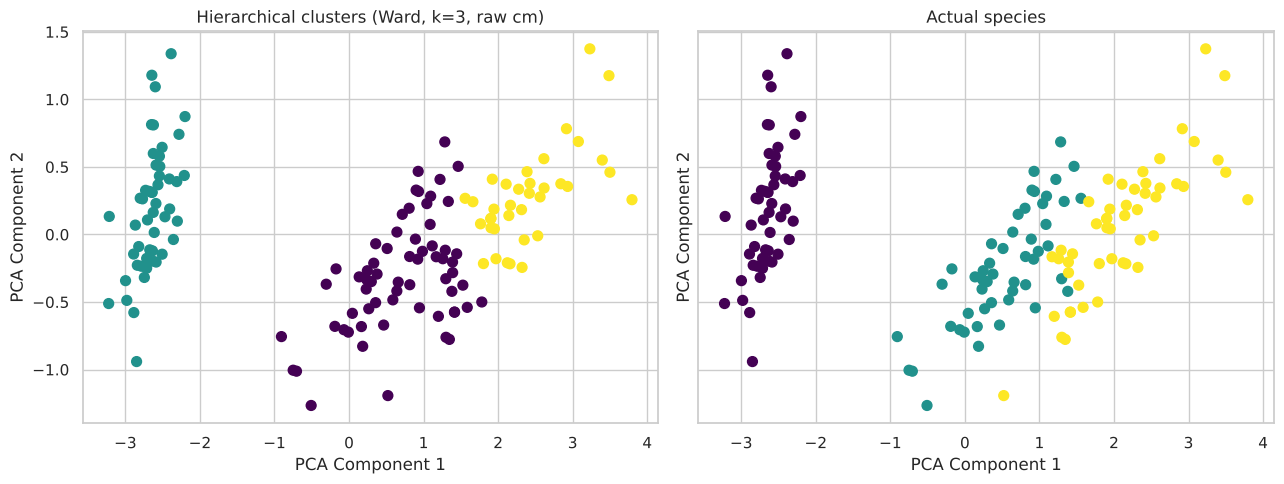

In [12]:
# PCA is used for display only; clustering was done on the full 4-D data
pca = PCA(n_components=2)
X_pca = pca.fit_transform(iris_raw)
print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.round(3), "total", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=50); axes[0].set_title("Hierarchical clusters (Ward, k=3, raw cm)")
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=true_labels, cmap='viridis', s=50); axes[1].set_title("Actual species")
for ax in axes: ax.set_xlabel("PCA Component 1"); ax.set_ylabel("PCA Component 2")
plt.tight_layout(); plt.show()

### Comparing clusters with species

Cluster ids are arbitrary, so a *confusion matrix* (which assumes cluster 0 means class 0) is the wrong tool. A **contingency table** shows how species distribute across clusters, and ARI / NMI summarise agreement independent of label numbering.

In [13]:
print(pd.crosstab(pd.Series(iris.target_names[true_labels], name='species'), pd.Series(labels, name='cluster')))
print(f"\nAdjusted Rand index: {adjusted_rand_score(true_labels, labels):.3f}")
print(f"Normalised mutual information: {normalized_mutual_info_score(true_labels, labels):.3f}")
print(f"Silhouette: {silhouette_score(iris_raw, labels):.3f}")

cluster      0   1   2
species               
setosa       0  50   0
versicolor  49   0   1
virginica   15   0  35

Adjusted Rand index: 0.731
Normalised mutual information: 0.770
Silhouette: 0.554


## Summary

- Hierarchical clustering builds nested clusters via **dendrograms**; the number of clusters is chosen by cutting the tree (silhouette, dendrogram gaps and domain knowledge all help; they need not agree).
- Ward linkage is a good default; single linkage is prone to chaining.
- Scaling should be checked rather than assumed: distance-based methods are scale-sensitive, but on Iris (all features in cm) standardising lowered agreement with the species.
- Clustering results are validated with silhouette (no labels) and ARI / NMI plus a contingency table (labels available), **not** with accuracy or a confusion matrix.

**Limits:** Iris is small, clean and low-dimensional. Hierarchical clustering needs O(n²) memory, so it does not scale to large datasets.